In [1]:
from transformers import AutoModelForImageTextToText, AutoProcessor, BitsAndBytesConfig
from transformers.modeling_flash_attention_utils import lazy_import_flash_attention
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchcodec.decoders import VideoDecoder


In [2]:
import ctypes, glob, os

ffmpeg_lib = os.path.expanduser("~/ffmpeg-shared/lib")

for name in ["libavutil", "libswresample", "libswscale", "libpostproc",
             "libavcodec", "libavformat", "libavfilter", "libavdevice"]:
    for path in sorted(glob.glob(f"{ffmpeg_lib}/{name}.so.*")):
        if path.count(".so.") == 1 and path.split(".so.")[1].isdigit():
            try:
                ctypes.CDLL(path, mode=ctypes.RTLD_GLOBAL)
            except OSError as e:
                print("nie załadowano:", path, e)

import torchcodec
print("torchcodec ok", torchcodec.__version__)

torchcodec ok 0.2.1


In [3]:
# We recommend enabling flash_attention_2 for better acceleration and memory saving, especially in multi-image and video scenarios.
model = AutoModelForImageTextToText.from_pretrained(
    "Qwen/Qwen3.8-27B",
    dtype=torch.bfloat16,
    attn_implementation="flash_attention_2",
    device_map="auto"
    )

processor = AutoProcessor.from_pretrained("Qwen/Qwen3.8-27B")

Current Triton version 3.2.0 is below the recommended 3.3.0 version. Errors may occur and these issues will not be fixed. Please consider upgrading Triton.


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

In [4]:
print(model.generation_config)

GenerationConfig {
  "bos_token_id": 248044,
  "do_sample": true,
  "eos_token_id": [
    248046,
    248044
  ],
  "pad_token_id": 248044,
  "temperature": 1.0,
  "top_k": 20,
  "top_p": 0.95
}



In [5]:
prompt = """Dostajesz nagranie z kamery monitoringu miejskiego. Obserwujesz na nim drogę wraz z przejściem dla pieszych. Przeanalizuj podane nagranie zwracając szczególną uwagę na sytuacje niebezpieczne takie jak:
- samochody przejeżdżające przez przejście dla pieszych w momencie gdy znajduje się na nim pieszy - typ 1
- samochód nie ustępuje pierwszeństwa pieszemu (pieszy czeka przed przejściem a samochód jedzie) - typ 2
- samochód przekracza ciągłą linię oddzielającą pasy ruchu - typ 3
Wynik zwróć w postaci tagów XML w którym każde zdarzenie zostanie zapisane w tagu <incident>. Każdy incydent powinien zawierać następujące atrybuty: typ (w tagu <type>), czas zdarzenia (w tagu <time>). Wszystkie zdarzenia powinny być zapisane w tagu <incidents>.

Struktura wyjściowa pliku XML powinna wyglądać następująco:
<incidents>
  <incident>
    <type>[numer_typu]</type>
    <time>[znacznik_czasu]</time>
  </incident>
</incidents>

Jeśli nie wystąpiły żadne incydenty, zwróć pusty tag <incidents></incidents>."""

In [6]:
def prepare_answear(messages):
    # Preparation for inference
    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
        reasoning_effort="medium"
    )
    inputs = inputs.to(model.device)

    # Inference: Generation of the output
    generated_ids = model.generate(**inputs, max_new_tokens=12288)
    generated_ids_trimmed = [
        out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )
    return output_text[0]

In [ ]:
def sampled_indices(video_path, fps=None, default_fps=2, min_frames=4, max_frames=768, temporal_patch=2):
    """Odtwarza logikę próbkowania z video processora Qwen-VL."""
    dec = VideoDecoder(video_path)
    total = dec.metadata.num_frames
    src_fps = dec.metadata.average_fps
    target_fps = fps if fps is not None else default_fps

    n = int(total / src_fps * target_fps)
    n = min(max(n, min_frames), max_frames, total)
    n = n - n % temporal_patch                      # liczba klatek musi być podzielna przez 2
    idx = torch.arange(0, total, total / n).int().tolist()
    return dec, idx, src_fps

def preview_frames(video_path, fps=None, cols=3, thumb_w=3.0, **kw):
    dec, idx, src_fps = sampled_indices(video_path, fps, **kw)
    frames = dec.get_frames_at(indices=idx).data    # (N, C, H, W), uint8
    rows = int(np.ceil(len(idx) / cols))
    h, w = frames.shape[2], frames.shape[3]

    fig, axes = plt.subplots(rows, cols, figsize=(cols * thumb_w, rows * thumb_w * h / w), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, f, i in zip(axes.ravel(), frames, idx):
        ax.imshow(f.permute(1, 2, 0).numpy())
        ax.set_title(f"#{i} | {i / src_fps:.2f}s", fontsize=9)
    fig.suptitle(f"{video_path} | fps={fps if fps is not None else 'domyślne'} | {len(idx)} klatek", y=1.0)
    plt.tight_layout()
    plt.show()

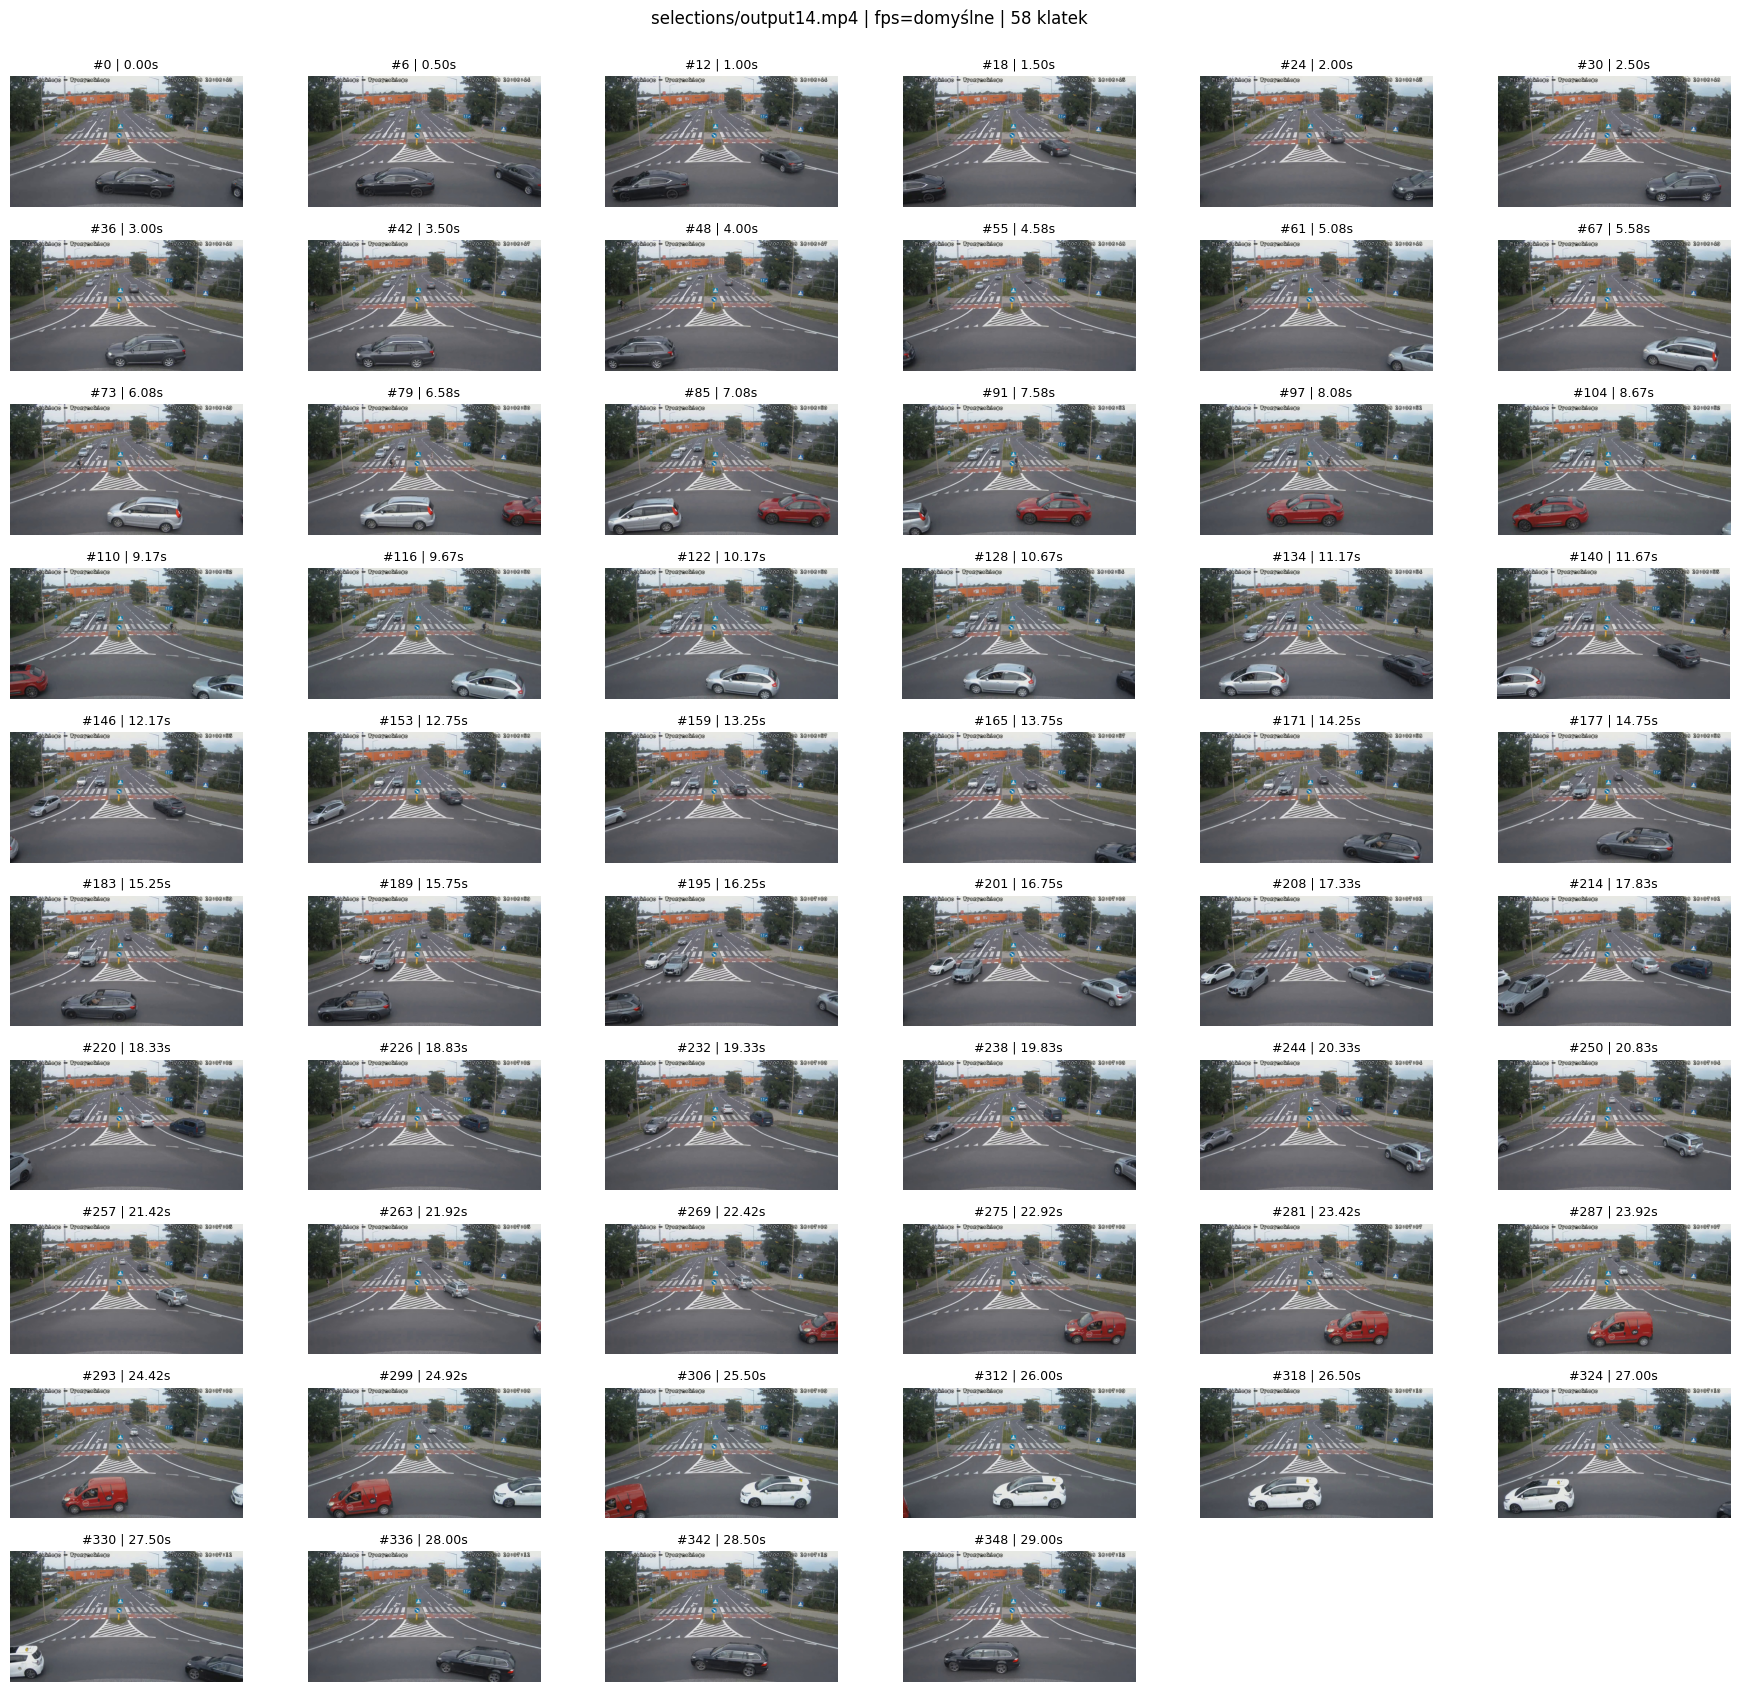

[transformers] Qwen3VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


The user wants me to analyze a traffic camera video and detect specific unsafe situations: type 1 (car crossing pedestrian crossing while pedestrian is on it), type 2 (car not yielding to pedestrian waiting at crossing), type 3 (car crossing solid line separating lanes).

Let me carefully watch the video frame by frame.

The video shows a road intersection with pedestrian crossings. The timestamp runs from 16:06:44 to 16:07:13.

Let me track pedestrians and cyclists on the crosswalks.

At around 16:06:44-45, there's a pedestrian on the right side crosswalk area? Let's look. At the start, on the right crosswalk, there's a pedestrian walking. Actually I see a person near the right crossing around 06:45-06:48.

Let me look at the cyclist. Around 16:06:47-52, a cyclist crosses from left to right on the crosswalk. At 16:06:47 the cyclist is on the left crosswalk moving right. By 16:06:50-51 the cyclist is in the middle/right of the crosswalk. During this time, are cars crossing the crosswal

In [8]:
# Messages containing a video url(or a local path) and a text query
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": "selections/output14.mp4",
                #"fps": 2
            },
            {"type": "text", 
             "text": prompt
            },
        ],
    }
]

preview_frames("selections/output14.mp4")
print(prepare_answear(messages))

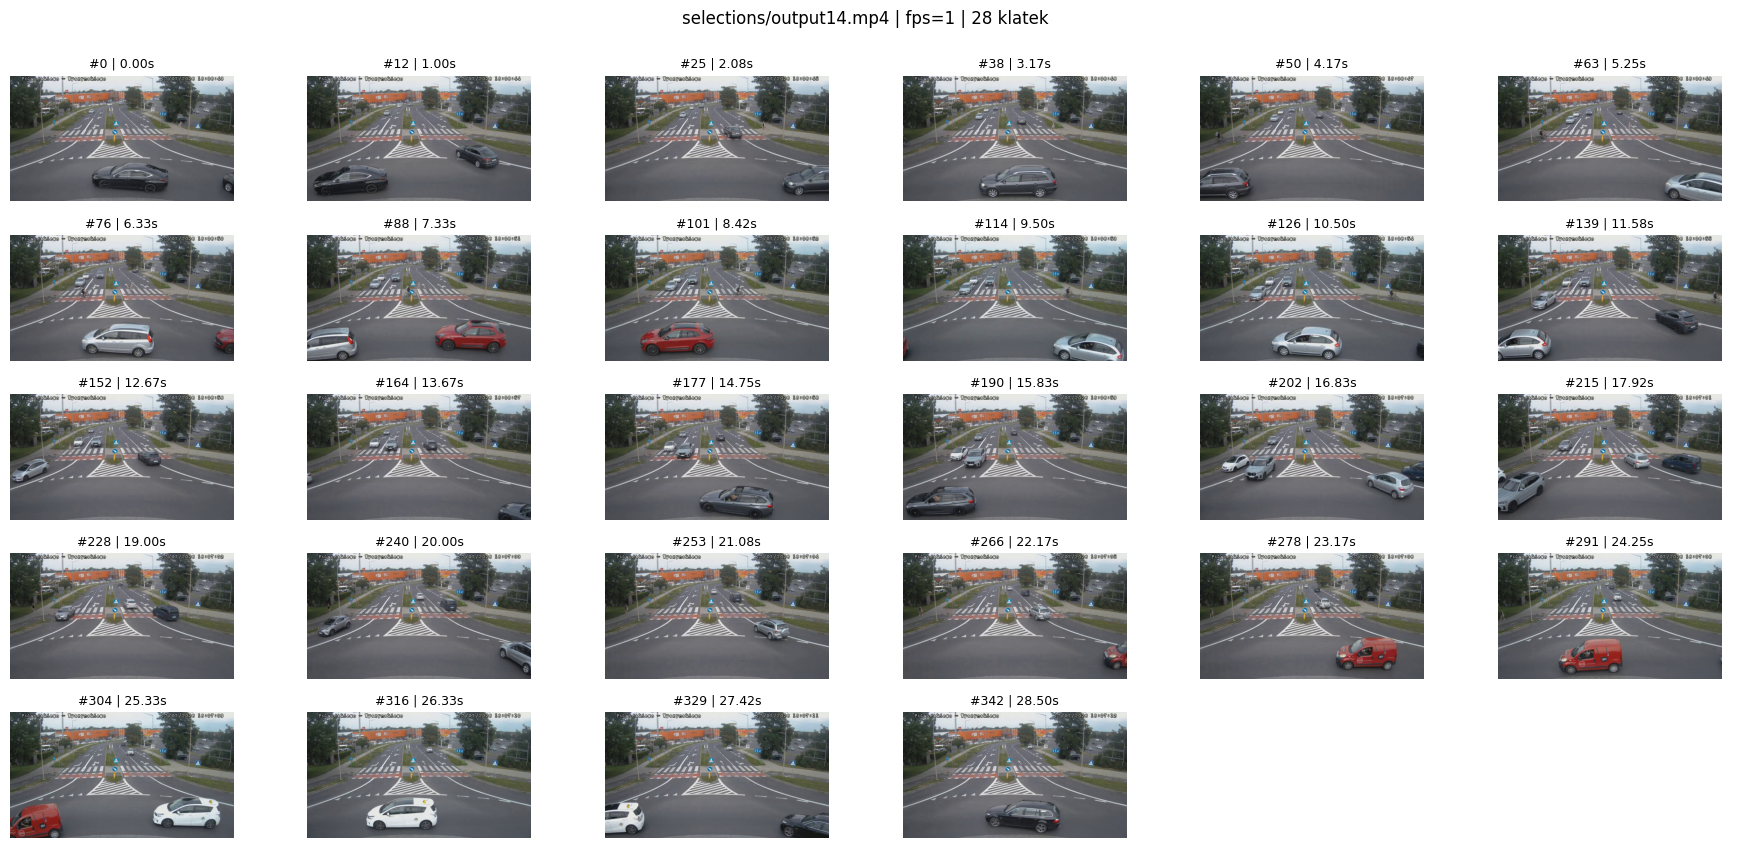

The user wants me to analyze a surveillance video of a road intersection with a pedestrian crossing and identify specific dangerous situations:
- Type 1: car crossing the pedestrian crossing while a pedestrian is on it
- Type 2: car not yielding to pedestrian (pedestrian waiting before crossing, car drives through)
- Type 3: car crossing the continuous line separating lanes

Let me carefully watch the video frame by frame.

Looking at the frames:
- 00:00-00:04: A black sedan passes, then a gray station wagon. Two pedestrians are walking on the right sidewalk area, not at the crossing.
- 00:04-00:08: A cyclist enters the crossing from the left side. The cyclist crosses the pedestrian crossing. There are cars approaching from the left lane. Let's look: at 00:05 a silver car is in the left lane stopped? Actually the cyclist is crossing. A silver minivan passes in the foreground (right lane direction). The cyclist is on the crossing from left to right.
- Around 00:05-00:09: The cyclist is 

In [9]:
# Messages containing a video url(or a local path) and a text query
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": "selections/output14.mp4",
                "fps": 1
            },
            {"type": "text", 
             "text": prompt
            },
        ],
    }
]

preview_frames("selections/output14.mp4", fps=1)
print(prepare_answear(messages))

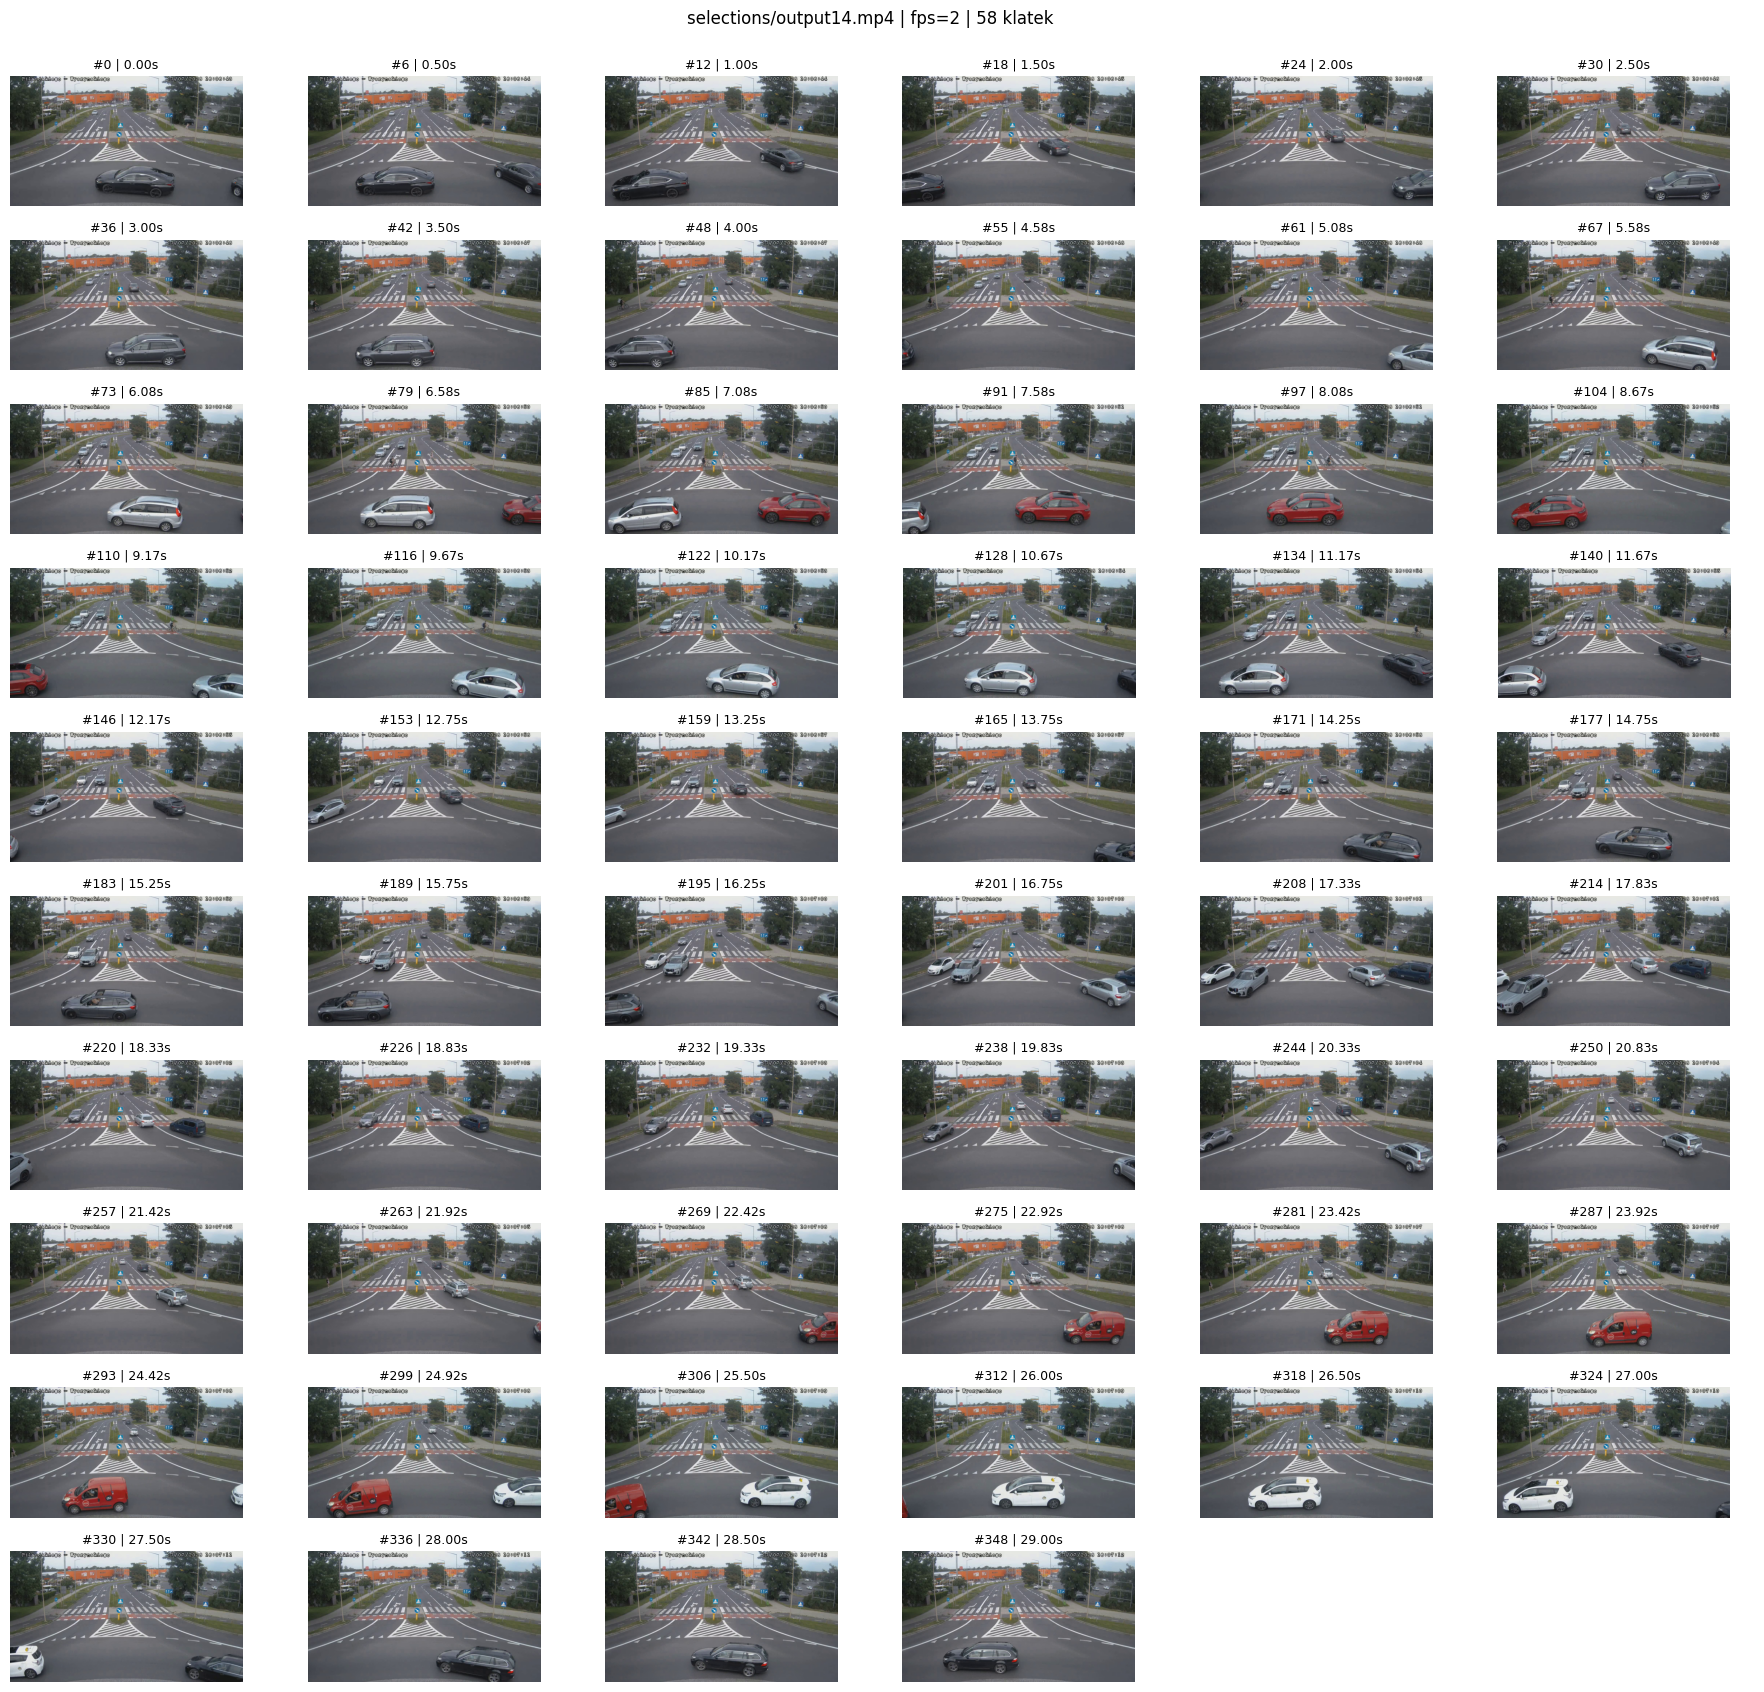

In [ ]:
# Messages containing a video url(or a local path) and a text query
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": "selections/output14.mp4",
                "fps": 2
            },
            {"type": "text", 
             "text": prompt
            },
        ],
    }
]

preview_frames("selections/output14.mp4", fps=2)
print(prepare_answear(messages))

In [ ]:
# Messages containing a video url(or a local path) and a text query
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": "selections/output14.mp4",
                "fps": 4
            },
            {"type": "text", 
             "text": prompt
            },
        ],
    }
]

preview_frames("selections/output14.mp4", fps=4)
print(prepare_answear(messages))

NameError: name 'preview_frames' is not defined

In [ ]:
# Messages containing a video url(or a local path) and a text query
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": "selections/output14.mp4",
                "fps": 0.5
            },
            {"type": "text", 
             "text": prompt
            },
        ],
    }
]

preview_frames("selections/output14.mp4", fps=0.5)
print(prepare_answear(messages))

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Okay, let's tackle this problem. So, I need to analyze the traffic camera footage and identify three specific types of incidents: Type 1, Type 2, and Type 3. The user provided a video description, but I don't have the actual video. Wait, the problem states that I have the recording from the traffic camera, but the user provided a sequence of frames with timestamps. Hmm, maybe the video frames are described in the problem statement.

Wait, the user included a series of frames with timestamps from 0.0 to 57.7 seconds. Each frame shows cars moving through an intersection with a crosswalk. The task is to check for three types of incidents:

1. Cars crossing the crosswalk while a pedestrian is present (Type 1)
2. A car not yielding to a pedestrian waiting at the crosswalk (Type 2)
3. A car crossing the continuous line separating lanes (Type 3)

First, I need to check if any of these incidents occurred. Since I don't have the actual video, but the problem gives the frame-by-frame description

In [ ]:
# Messages containing a video url(or a local path) and a text query
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": "selections/output14.mp4",
                "fps": 0.25
            },
            {"type": "text", 
             "text": prompt
            },
        ],
    }
]

preview_frames("selections/output14.mp4", fps=0.25)
print(prepare_answear(messages))

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Okay, let's tackle this problem. I need to analyze the provided traffic camera footage and identify any incidents based on the three types specified: Type 1, Type 2, and Type 3.

First, I'll go through the video description. The user mentioned that the video shows a crosswalk (przejście dla pieszych) with various cars passing through. The task is to check for three specific incidents.

Let me recall the types:
- Type 1: Cars crossing the crosswalk when a pedestrian is present.
- Type 2: Car not yielding to pedestrians (pedestrian waiting, car goes through).
- Type 3: Car crossing the continuous line separating lanes.

I need to check each frame to see if any of these occur.

Starting with the video. The timestamp starts at 16:00:00 on 17/07/2023. The description gives timestamps for each second, but maybe the key is to look for when a pedestrian is present at the crosswalk and a car goes through.

Wait, in the video description, the user says "Obserwujesz na nim drogę wraz z przejściem